In [2]:
import os

In [3]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [4]:
def load_raw_gmsh_nodes(file_path):
    nodes = []
    reading_nodes = False
    
    with open(file_path, 'r') as f:
        for line in f:
            line = line.strip()
            if line == "$Nodes":
                reading_nodes = True
                next(f) # Skip the line containing the total no. of nodes
                continue
            if line == "$EndNodes":
                reading_nodes = False
                break
            
            if reading_nodes:
                parts = line.split()
                # MSH 2.2 format for a node line:
                if len(parts) == 4:
                    try:
                        x = float(parts[1])
                        y = float(parts[2])
                        z = float(parts[3])
                        nodes.append([x, y, z])
                    except ValueError:
                        continue
                    
    return np.array(nodes)
                

1. Reading the .msh file and assigning the node coords
2. Check wheather the imported data matches the original data or not.

Successfully extracted 51484 raw node coords directly.

Raw Geometric Bounds Check
X range: [-501.0000 to -13.1421]
Y range: [-303.9914 to -89.9647]
Z range: [-0.1199 to 171.3792]


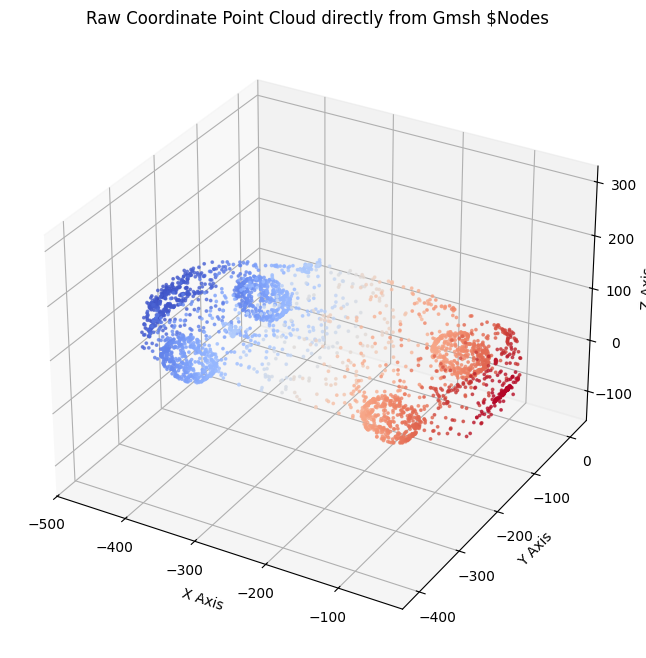

In [5]:
mesh_file = "assembly.msh"
try:
    all_points = load_raw_gmsh_nodes(mesh_file)
    print(f"Successfully extracted {len(all_points)} raw node coords directly.")
except Exception as e:
    print(f"Error reading file directly: {e}")
    all_points = np.array([])
    
if len(all_points) > 0:
    # 2. Print exact geometric extreme bounds
    print("\n" + "="*40)
    print("Raw Geometric Bounds Check")
    print("="*40)
    print(f"X range: [{all_points[:, 0].min():.4f} to {all_points[:, 0].max():.4f}]")
    print(f"Y range: [{all_points[:, 1].min():.4f} to {all_points[:, 1].max():.4f}]")
    print(f"Z range: [{all_points[:, 2].min():.4f} to {all_points[:, 2].max():.4f}]")
    print("="*40)
        
    # 3. Downsample to safely plot without lagging
    downsample_rate = max(1, len(all_points) // 3000)
    plot_nodes = all_points[::downsample_rate]
    
    # 4. Generating the direct Point distribution plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    scatter  = ax.scatter(
        plot_nodes[:, 0],
        plot_nodes[:, 1],
        plot_nodes[:, 2],
        c=plot_nodes[:, 0],# Color profile mapped across X-axis variation
        cmap='coolwarm',
        s=3,
        alpha=0.7
    )
    ax.set_title("Raw Coordinate Point Cloud directly from Gmsh $Nodes", fontsize=12)
    ax.set_xlabel("X Axis")
    ax.set_ylabel("Y Axis")
    ax.set_zlabel("Z Axis")
    
    # Force equal aspect ratio display so it's not distorted visually
    max_range = np.array([plot_nodes[:,0].max()-plot_nodes[:,0].min(), 
                          plot_nodes[:,1].max()-plot_nodes[:,1].min(), 
                          plot_nodes[:,2].max()-plot_nodes[:,2].min()]).max() / 2.0
    mid_x = (plot_nodes[:,0].max()+plot_nodes[:,0].min()) * 0.5
    mid_y = (plot_nodes[:,1].max()+plot_nodes[:,1].min()) * 0.5
    mid_z = (plot_nodes[:,2].max()+plot_nodes[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)

    plt.show()

    
    
    

Extract the points and dynamically calculate the bounding box of the model

In [6]:
mesh_file = "assembly.msh"
model_points = load_raw_gmsh_nodes(mesh_file)

x_min, x_max = model_points[:, 0].min(), model_points[:, 0].max()
y_min, y_max = model_points[:, 1].min(), model_points[:, 1].max()
z_min, z_max = model_points[:, 2].min(), model_points[:, 2].max()

L = x_max - x_min # Length of the model along flow direction X
H = y_max - y_min  # Width of the model along Y
W = z_max - z_min  # Height of the model along Z

print(f"Model dimensions detected: Length={L:.2f}, Height={W:.2f}, Width={H:.2f}")

Model dimensions detected: Length=487.86, Height=171.50, Width=214.03


Defining the Wind Tunnel Box Dimensions


In [7]:
tunnel_xmin = x_min - (0.5 * L) 
tunnel_xmax = x_max + (0.5 * L)  
tunnel_ymin = y_min - 70            
tunnel_ymax = y_max + 70
tunnel_zmin = z_min  
tunnel_zmax = z_max + (0.5 * W)  


Create the deepxde mathematical bounding geometry for tunnel and converting the model points to a PointCloud Geometry

In [8]:
wind_tunnel_box = dde.geometry.Cuboid(
    [tunnel_xmin, tunnel_ymin, tunnel_zmin],
    [tunnel_xmax, tunnel_ymax, tunnel_zmax]
)

model_geom = dde.geometry.PointCloud(points=model_points, boundary_points=model_points)

EXCLUDE MODEL: Create Fluid Domain via Subtraction (Wind Tunnel minus Model)

In [9]:
# Create a custom geometry logic class to override DeepXDE's sampling
class CleanFluidDomain(dde.geometry.CSGDifference):
    def inside(self, x):
        # Check if points are inside the overall wind tunnel
        in_tunnel = self.geom1.inside(x)
        
        # Manually define a mask for the space inside the model boundaries
        # This prevents the neural network from placing fluid points inside the car
        is_inside_object = (x[:, 0] >= x_min) & (x[:, 0] <= x_max) & \
                            (x[:, 1] >= y_min) & (x[:, 1] <= y_max) & \
                            (x[:, 2] >= z_min) & (x[:, 2] <= z_max)
        
        return in_tunnel & ~is_inside_object

# Instantiate your domain using this stricter exclusion rule
fluid_domain = CleanFluidDomain(wind_tunnel_box, model_geom)

# fluid_domain = dde.geometry.CSGDifference(wind_tunnel_box, model_geom)

Defining a 3D Incompressible Navier-Stokes Equations with a Reynold's number 500

In [10]:
def navier_stokes_3d(x, y):
    re = 500.0 
    nu = 1.0 / re 
    u, v, w, p = y[:, 0:1], y[:, 1:2], y[:, 2:3], y[:, 3:4]

    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1)
    du_z = dde.grad.jacobian(y, x, i=0, j=2)
    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    dv_z = dde.grad.jacobian(y, x, i=1, j=2)
    dw_x = dde.grad.jacobian(y, x, i=2, j=0)
    dw_y = dde.grad.jacobian(y, x, i=2, j=1)
    dw_z = dde.grad.jacobian(y, x, i=2, j=2)
    dp_x = dde.grad.jacobian(y, x, i=3, j=0)
    dp_y = dde.grad.jacobian(y, x, i=3, j=1)
    dp_z = dde.grad.jacobian(y, x, i=3, j=2)

    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    du_zz = dde.grad.hessian(y, x, component=0, i=2, j=2)
    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    dv_zz = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dw_xx = dde.grad.hessian(y, x, component=2, i=0, j=0)
    dw_yy = dde.grad.hessian(y, x, component=2, i=1, j=1)
    dw_zz = dde.grad.hessian(y, x, component=2, i=2, j=2)

    continuity = du_x + dv_y + dw_z
    x_momentum = (u * du_x + v * du_y + w * du_z) + dp_x - nu * (du_xx + du_yy + du_zz)
    y_momentum = (u * dv_x + v * dv_y + w * dv_z) + dp_y - nu * (dv_xx + dv_yy + dv_zz)
    z_momentum = (u * dw_x + v * dw_y + w * dw_z) + dp_z - nu * (dw_xx + dw_yy + dw_zz)

    return [continuity, x_momentum, y_momentum, z_momentum]


Defining Wind Tunnel Boundary Filters

In [11]:
def boundary_inlet(x, on_boundary):
    return on_boundary and np.isclose(x[0], tunnel_xmin)

def boundary_outlet(x, on_boundary):
    return on_boundary and np.isclose(x[0], tunnel_xmax)

def boundary_tunnel_walls(x, on_boundary):
    # Top, Bottom and Side walls of the tunnel box
    is_wall = np.isclose(x[1], tunnel_ymin) or np.isclose(x[1], tunnel_ymax) or \
        np.isclose(x[2], tunnel_zmin) or np.isclose(x[2], tunnel_zmax)
        
    return on_boundary and is_wall


Creating Boundry of Model Surface

In [12]:
def boundary_model_surface(x, on_boundary):
    # The CAD surface is the internal boundary of the combined geometry.
    # It is on the boundary of 'geom', but NOT on the tunnel walls.
    return on_boundary and not boundary_tunnel_walls(x, on_boundary)
    

Apllying Physical Boundary Conditions

In [13]:
U_inlet = 1.0 # Freestream wind velocity entering tunnel along X-axis

# Component mapping: 0=u, 1=v, 2=w, 3=p

bc_inlet_u = dde.icbc.DirichletBC(fluid_domain, lambda x: U_inlet, boundary_inlet, component=0)
bc_inlet_v = dde.icbc.DirichletBC(fluid_domain, lambda x: 0.0, boundary_inlet, component=1)
bc_inlet_w = dde.icbc.DirichletBC(fluid_domain, lambda x: 0.0, boundary_inlet, component=2)

bc_outlet_p = dde.icbc.DirichletBC(fluid_domain, lambda x: 0.0, boundary_outlet, component=3)

bc_tunnel_u = dde.icbc.DirichletBC(fluid_domain, lambda x: U_inlet, boundary_tunnel_walls, component=0)
bc_tunnel_v = dde.icbc.DirichletBC(fluid_domain, lambda x: 0.0, boundary_tunnel_walls, component=1)
bc_tunnel_w = dde.icbc.DirichletBC(fluid_domain, lambda x: 0.0, boundary_tunnel_walls, component=2)

dense_model_points = model_points[::10] # Reducing the size of the points for the system to work properly

# 2. Re-create the solid-wall boundary conditions
bc_model_u = dde.icbc.PointSetBC(dense_model_points, 0.0, component=0)
bc_model_v = dde.icbc.PointSetBC(dense_model_points, 0.0, component=1)
bc_model_w = dde.icbc.PointSetBC(dense_model_points, 0.0, component=2)



bcs = [
    bc_inlet_u, bc_inlet_v, bc_inlet_w,
    bc_outlet_p,
    bc_tunnel_u, bc_tunnel_v, bc_tunnel_w,
    bc_model_u, bc_model_v, bc_model_w  
]

Combine all the data and define the loss_weights

In [14]:
data = dde.data.PDE(
    wind_tunnel_box,
    navier_stokes_3d,
    bcs,
    num_domain=3000,     # Low domain count to establish a baseline
    num_boundary=700,
)



In [38]:
loss_weights = [
    1.0, 1.0, 1.0, 1.0,    # Navier-Stokes equations
    5.0, 2.0, 2.0, 1.0,        # Inlet & Outlet constraints
    1.0, 2.0, 2.0,             # Outer Tunnel Walls
    109.0, 70.0, 60.0        # FIX: Force No-slip on the Car Surface with high weight!
]

Visualising the Distribution of the points for training

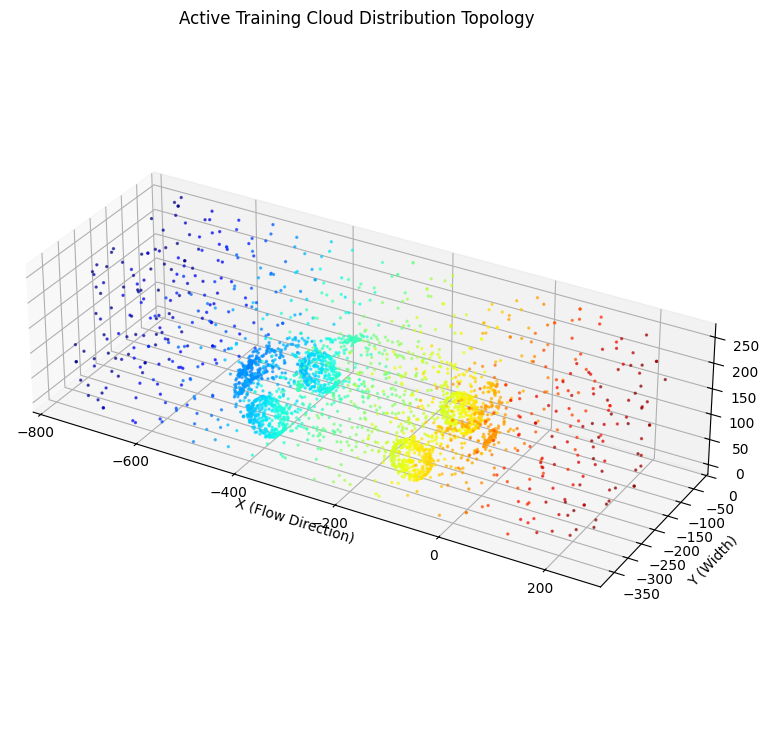

In [39]:
x_train = data.train_x

# Use a safe slicing step ONLY for the 3D viewport plotting loop 
# so your computer screen doesn't freeze up while rendering the interactive window
plot_step = max(1, len(x_train) // 3000)
visual_points = x_train[::plot_step]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Render the active point configuration
ax.scatter(
    visual_points[:, 0], visual_points[:, 1], visual_points[:, 2],
    c=visual_points[:, 0], cmap='jet', s=2, alpha=0.6
)

ax.set_xlabel('X (Flow Direction)')
ax.set_ylabel('Y (Width)')
ax.set_zlabel('Z (Height)')
ax.set_title("Active Training Cloud Distribution Topology")
ax.set_box_aspect([tunnel_xmax - tunnel_xmin, tunnel_ymax - tunnel_ymin, tunnel_zmax - tunnel_zmin])

plt.show()

Defining the Neural Network and Compiling the model

In [40]:
layer_size = [3, 256, 128, 128, 4]
net = dde.nn.FNN(layer_size, "tanh", "Glorot uniform")

model = dde.Model(data, net)


We can make Loss Weights as constants, instead we can make them adaptive So we need to create a class for generating Self Adaptive Weights through a Callback function during training

In [41]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        exp_terms = np.exp(self.alpha * np.array(current_losses))
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

In [27]:
resampler_callback = dde.callbacks.PDEPointResampler(period=100)

Compiling the Model and Training

In [42]:
model.compile("adam", lr=1e-3, loss_weights=loss_weights)
losshistory, train_state = model.train(iterations=2000,display_every=300, callbacks=[adaptive_callback, resampler_callback])

# dde.optimizers.config.set_LBFGS_options(maxiter=2000)
# model.compile("L-BFGS", loss_weights=model.loss_weights)
# losshistory, train_state = model.train(display_every=50, callbacks=[adaptive_callback])
# # i = 0
# for i in range(1):
#     model.compile("adam", lr=1e-3, loss_weights=model.loss_weights)
#     losshistory, train_state = model.train(iterations=500,display_every=300, callbacks=[adaptive_callback, resampler_callback])

#     dde.optimizers.config.set_LBFGS_options(maxiter=3000)
#     model.compile("L-BFGS", loss_weights=model.loss_weights)
#     losshistory, train_state = model.train(display_every=50, callbacks=[adaptive_callback])
#     i += 1




Compiling model...
'compile' took 0.000727 s

Training model...

Step      Train loss                                                                                                                                      Test loss                                                                                                                                       Test metric
0         [1.69e-04, 1.65e-04, 1.00e-04, 1.57e-04, 6.53e+00, 1.56e+00, 5.58e-01, 5.88e-01, 1.48e+00, 1.69e+00, 3.96e-01, 1.05e+01, 5.99e+01, 1.20e+01]    [1.70e-04, 1.65e-04, 1.00e-04, 1.57e-04, 6.53e+00, 1.56e+00, 5.58e-01, 5.88e-01, 1.48e+00, 1.69e+00, 3.96e-01, 1.05e+01, 5.99e+01, 1.20e+01]    []  
300       [1.37e-30, 1.74e-30, 1.27e-30, 1.47e-30, 1.44e-24, 3.09e-28, 3.10e-26, 5.53e-27, 1.47e-26, 1.44e-27, 1.57e-26, 2.36e-22, 1.32e-03, 1.28e-21]    [1.37e-30, 1.74e-30, 1.27e-30, 1.47e-30, 1.44e-24, 3.09e-28, 3.10e-26, 5.53e-27, 1.47e-26, 1.44e-27, 1.57e-26, 2.36e-22, 1.32e-03, 1.28e-21]    []  


KeyboardInterrupt: 

Visualizing the loss history to verify optimization convergence

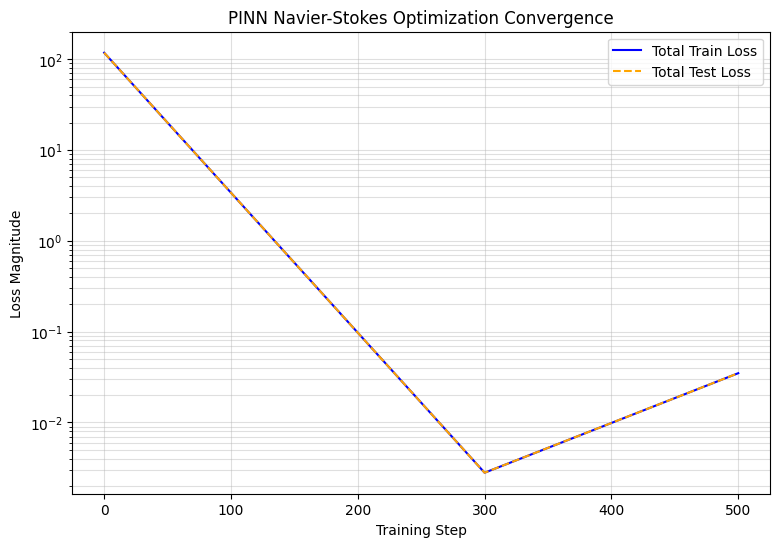

In [ ]:
loss_train = np.sum(losshistory.loss_train, axis=1)
loss_test = np.sum(losshistory.loss_test, axis=1)

plt.figure(figsize=(9, 6))
plt.plot(losshistory.steps, loss_train, label="Total Train Loss", color='blue')
plt.plot(losshistory.steps, loss_test, label="Total Test Loss", linestyle='--', color='orange')
plt.yscale('log')
plt.xlabel("Training Step")
plt.ylabel("Loss Magnitude")
plt.title("PINN Navier-Stokes Optimization Convergence")
plt.grid(True, which="both", ls="-", alpha=0.4)
plt.legend()
plt.show()

Rendering loss tracking timeline graphs...


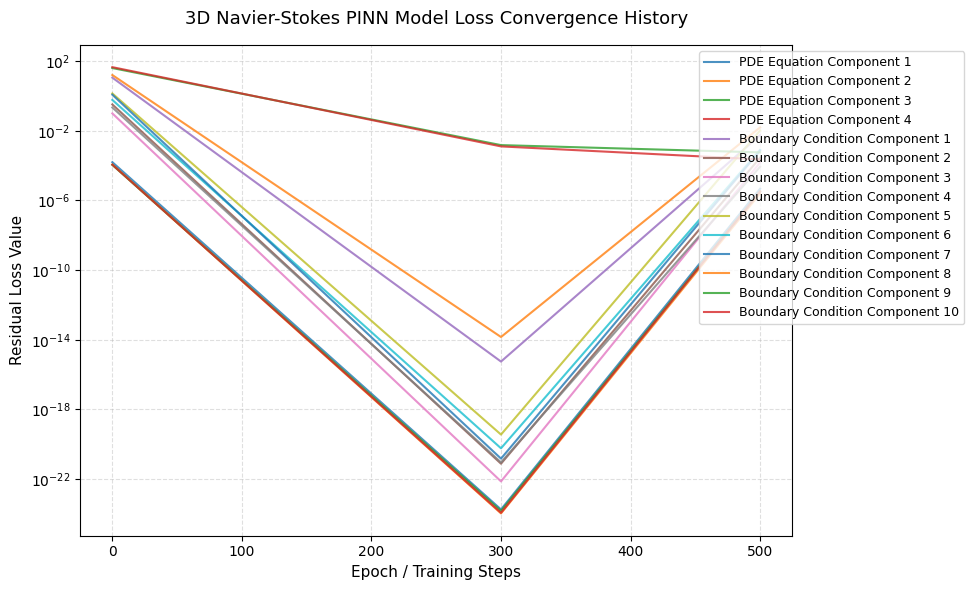

In [ ]:
# 1. Access the saved loss data arrays from your DeepXDE training history
# (Ensure you ran: losshistory, train_state = model.train(...) before this)
steps = np.array(losshistory.steps)
loss_train = np.array(losshistory.loss_train)  # Shape: (Num_Steps, Num_Loss_Functions)

# 2. Set up the plotting window canvas
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Graph the individual loss tracks dynamically
# DeepXDE tracks PDE losses first, followed by BC losses
num_losses = loss_train.shape[1]

for i in range(num_losses):
    if i < 4:
        # The first 4 losses belong to the 3D Navier-Stokes equations
        label_name = f"PDE Equation Component {i+1}"
    else:
        # The remaining 7 losses belong to your PointSetBC constraints
        label_name = f"Boundary Condition Component {i-3}"
        
    ax.plot(steps, loss_train[:, i], label=label_name, alpha=0.8, linewidth=1.5)

# 4. Format the plot with a logarithmic scale (crucial for PINN optimization views)
ax.set_yscale("log")
ax.set_xlabel("Epoch / Training Steps", fontsize=11)
ax.set_ylabel("Residual Loss Value", fontsize=11)
ax.set_title("3D Navier-Stokes PINN Model Loss Convergence History", fontsize=13, pad=15)

# Style configuration
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0), fontsize=9)

plt.tight_layout()
print("Rendering loss tracking timeline graphs...")
plt.show()


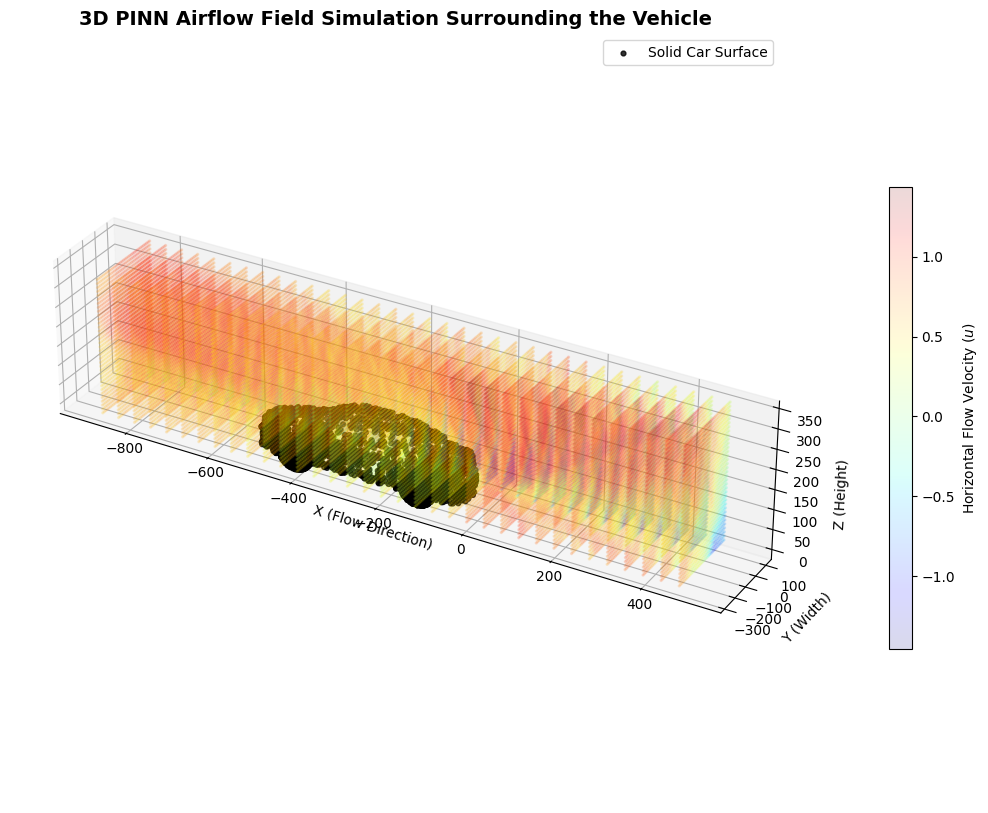

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Create a tight 3D sampling box focused strictly around the car area
# This avoids plotting the empty wind tunnel space so you can focus on the vehicle
num_points_axis = 35
x_sample = np.linspace(x_min - 0.75 * L, x_max + 1*L, num_points_axis)
y_sample = np.linspace(y_min, y_max + H, num_points_axis)
z_sample = np.linspace(z_min, z_max + W, num_points_axis)

X_m, Y_m, Z_m = np.meshgrid(x_sample, y_sample, z_sample)

# 2. Flatten into the [N, 3] matrix format expected by DeepXDE
flow_points = np.vstack((X_m.flatten(), Y_m.flatten(), Z_m.flatten())).T

# 3. Predict the velocity components using your trained network model
# predictions[:, 0] = u velocity field (flow direction)
predictions = model.predict(flow_points)
u_velocity = predictions[:, 0]

# 4. Generate the 3D Flow Field Viewport
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the air particles passing over and around the model
# Semitransparent points help you see through the air volume to see the car inside
air_scatter = ax.scatter(
    flow_points[:, 0], flow_points[:, 1], flow_points[:, 2],
    c=u_velocity, 
    cmap='jet', 
    s=2, 
    alpha=0.15
)

# 5. Overlay your fast_model_points as a solid black structural anchor
# This explicitly reveals the solid car boundary underneath the flow lines
ax.scatter(
    dense_model_points[:, 0], dense_model_points[:, 1], dense_model_points[:, 2],
    color='black', 
    s=12, 
    alpha=0.8,
    label='Solid Car Surface'
)

# 6. Add layout labels and matching scales to prevent geometric stretching
fig.colorbar(air_scatter, ax=ax, label='Horizontal Flow Velocity ($u$)', pad=0.1, shrink=0.6)
ax.set_xlabel('X (Flow Direction)')
ax.set_ylabel('Y (Width)')
ax.set_zlabel('Z (Height)')
ax.set_title('3D PINN Airflow Field Simulation Surrounding the Vehicle', fontsize=14, fontweight='bold')

# Ensure perfect spatial scaling proportion 
ax.set_box_aspect([3*L, H, 2*W])
ax.legend(loc='upper right')

plt.show()


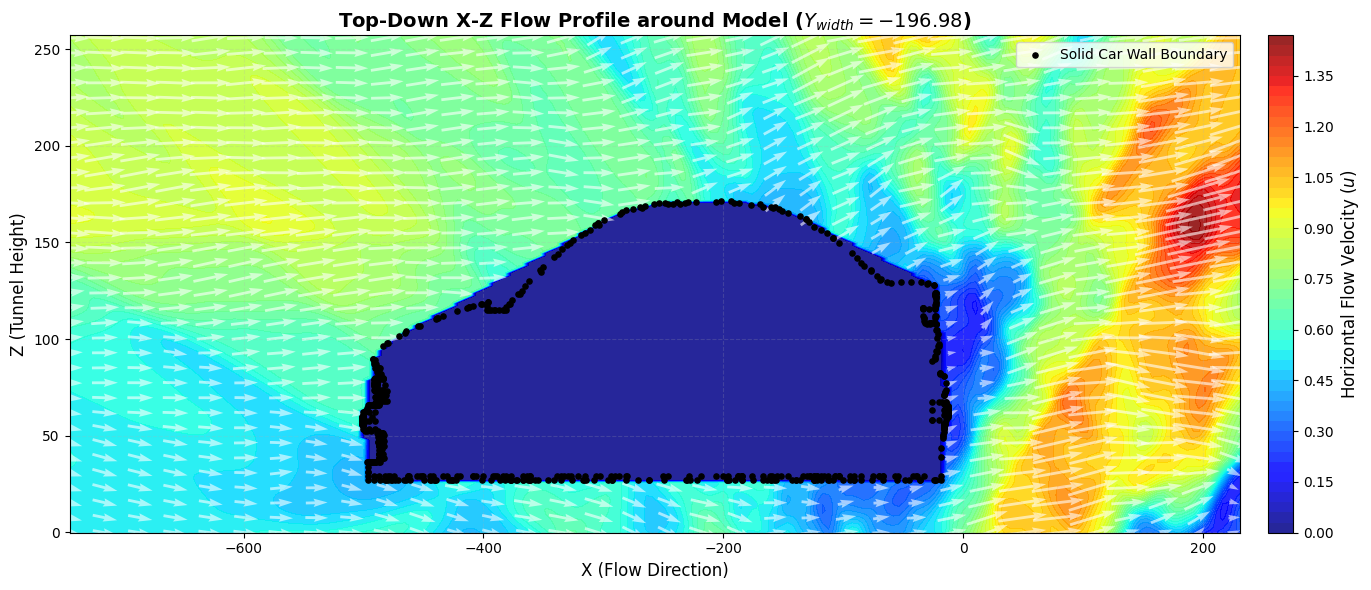

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

# 1. Target the exact middle height of your car model (Y-slice plane)
y_slice = (y_min + y_max) / 2.0

# 2. Generate a fine 2D evaluation grid along X (Flow) and Z (Width)
num_grid_points = 200
x_grid = np.linspace(tunnel_xmin, tunnel_xmax, num_grid_points)
z_grid = np.linspace(tunnel_zmin, tunnel_zmax, num_grid_points)
X_mesh, Z_mesh = np.meshgrid(x_grid, z_grid)

# 3. Flatten the mesh and hold Y constant to match DeepXDE's [N, 3] layout
X_flat = X_mesh.flatten()
Z_flat = Z_mesh.flatten()
Y_flat = np.full_like(X_flat, y_slice)

prediction_points = np.vstack((X_flat, Y_flat, Z_flat)).T

# 4. Predict the flow fields using your trained neural network
predictions = model.predict(prediction_points)
u_pred = predictions[:, 0].reshape(X_mesh.shape)
w_pred = predictions[:, 2].reshape(X_mesh.shape)

# 5. GEOMETRIC MASKING: Cleanly isolate the car footprint interior using ConvexHull + Matplotlib Path
y_tol = (y_max - y_min) * 0.15
car_slice_nodes = dense_model_points[np.abs(dense_model_points[:, 1] - y_slice) < y_tol]

if len(car_slice_nodes) > 3:
    from scipy.spatial import ConvexHull
    points_2d = car_slice_nodes[:, [0, 2]]  # Keep only X and Z coordinates
    hull = ConvexHull(points_2d)
    
    # Extract the boundary vertices in correct cyclic order
    hull_vertices = points_2d[hull.vertices]
    
    # FIX: Use matplotlib.path.Path to build the polygon check geometry
    hull_path = Path(hull_vertices)
    
    # Evaluate every grid node coordinate
    grid_coords = np.vstack((X_flat, Z_flat)).T
    is_inside_car = hull_path.contains_points(grid_coords).reshape(X_mesh.shape)
    
    # Zero out the velocities exactly within the solid body structure
    u_pred[is_inside_car] = 0.0
    w_pred[is_inside_car] = 0.0
else:
    is_inside_car = np.zeros_like(X_mesh, dtype=bool)

# 6. Render the top-down horizontal velocity contour map
plt.figure(figsize=(15, 6))
contour = plt.contourf(X_mesh, Z_mesh, u_pred, levels=50, cmap='jet', alpha=0.85)
cbar = plt.colorbar(contour, pad=0.02)
cbar.set_label('Horizontal Flow Velocity ($u$)', fontsize=12)

# 7. Plot Vector Arrows (Quivers) around the masked profile
u_quiver = np.where(is_inside_car, np.nan, u_pred)
w_quiver = np.where(is_inside_car, np.nan, w_pred)

stride = 6
plt.quiver(
    X_mesh[::stride, ::stride], 
    Z_mesh[::stride, ::stride], 
    u_quiver[::stride, ::stride], 
    w_quiver[::stride, ::stride], 
    color='white', 
    alpha=0.6, 
    scale=25, 
    pivot='mid'
)

# 8. Overlay the solid car geometry points directly on top
plt.scatter(
    car_slice_nodes[:, 0], 
    car_slice_nodes[:, 2], 
    color='black', 
    s=14, 
    label='Solid Car Wall Boundary', 
    zorder=10
)

# 9. Clean up visual boundaries and text labels
plt.xlabel('X (Flow Direction)', fontsize=12)
plt.ylabel('Z (Tunnel Height)', fontsize=12)
plt.title(f'Top-Down X-Z Flow Profile around Model ($Y_{{width}} = {y_slice:.2f}$)', fontsize=14, fontweight='bold')
plt.xlim(tunnel_xmin, tunnel_xmax)
plt.ylim(z_min, tunnel_zmax)
plt.grid(True, linestyle='--', alpha=0.2)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


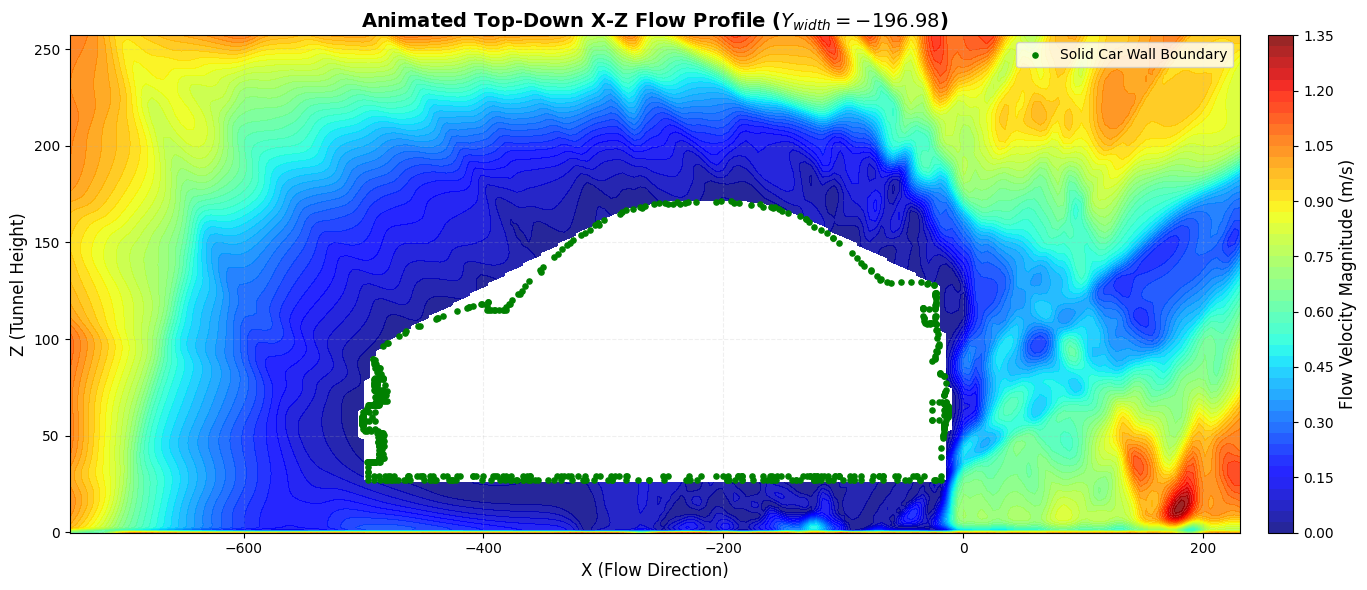

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.animation import FuncAnimation
from scipy.spatial import ConvexHull

# ==========================================
# 1. SETUP THE PLANE GRID 
# ==========================================
y_slice = (y_min + y_max) / 2.0

num_grid_points = 200
x_grid = np.linspace(tunnel_xmin, tunnel_xmax, num_grid_points)
z_grid = np.linspace(tunnel_zmin, tunnel_zmax, num_grid_points)
X_mesh, Z_mesh = np.meshgrid(x_grid, z_grid)

X_flat = X_mesh.flatten()
Z_flat = Z_mesh.flatten()
Y_flat = np.full_like(X_flat, y_slice)

prediction_points = np.vstack((X_flat, Y_flat, Z_flat)).T

# ==========================================
# 2. EVALUATE TRAINED PINN MODEL
# ==========================================
predictions = model.predict(prediction_points)
u_pred = predictions[:, 0].reshape(X_mesh.shape)
w_pred = predictions[:, 2].reshape(X_mesh.shape)

# ==========================================
# 3. APPLY YOUR GEOMETRIC CONVEX HULL MASK
# ==========================================
y_tol = (y_max - y_min) * 0.15
car_slice_nodes = dense_model_points[np.abs(dense_model_points[:, 1] - y_slice) < y_tol]

if len(car_slice_nodes) > 3:
    points_2d = car_slice_nodes[:, [0, 2]]
    hull = ConvexHull(points_2d)
    hull_vertices = points_2d[hull.vertices]
    hull_path = Path(hull_vertices)
    
    grid_coords = np.vstack((X_flat, Z_flat)).T
    is_inside_car = hull_path.contains_points(grid_coords).reshape(X_mesh.shape)
    
    # Force zero velocity inside the geometry domain to guide streamlines
    u_pred[is_inside_car] = 0.0
    w_pred[is_inside_car] = 0.0
else:
    is_inside_car = np.zeros_like(X_mesh, dtype=bool)

# Calculate velocity magnitude (speed) and set interior to NaN for visual background
velocity_magnitude = np.sqrt(u_pred**2 + w_pred**2)
velocity_magnitude[is_inside_car] = np.nan

# ==========================================
# 4. INITIALIZE ANIMATION CANVAS
# ==========================================
fig, ax = plt.subplots(figsize=(15, 6))

# Background contour plot using your chosen horizontal velocity mapping
contour = ax.contourf(X_mesh, Z_mesh, velocity_magnitude, levels=50, cmap='jet', alpha=0.85)
cbar = fig.colorbar(contour, ax=ax, pad=0.02)
cbar.set_label('Flow Velocity Magnitude (m/s)', fontsize=12)

# Scatter the green solid boundary nodes from your script directly on top
ax.scatter(
    car_slice_nodes[:, 0], 
    car_slice_nodes[:, 2], 
    color='green', 
    s=14, 
    label='Solid Car Wall Boundary', 
    zorder=10
)

# Extract stream paths using matplotlib's streamplot engine secretly (color='none')
stream = ax.streamplot(X_mesh, Z_mesh, u_pred, w_pred, color='none', density=1.6)
lines = stream.lines.get_paths()

# Parse vertex sequences along the flow lines
line_segments = [line.vertices for line in lines if len(line.vertices) > 1]

# Initialize individual thin black tracking lines that will move across the frame
plot_lines = [ax.plot([], [], color='black', alpha=0.5, linewidth=1.5)[0] for _ in line_segments]

# Formatting matches your design requirements
ax.set_xlabel('X (Flow Direction)', fontsize=12)
ax.set_ylabel('Z (Tunnel Height)', fontsize=12)
ax.set_title(f'Animated Top-Down X-Z Flow Profile ($Y_{{width}} = {y_slice:.2f}$)', fontsize=14, fontweight='bold')
ax.set_xlim(tunnel_xmin, tunnel_xmax)
ax.set_ylim(z_min, tunnel_zmax)
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc='upper right')

# ==========================================
# 5. ANIMATION ENGINE LOOP
# ==========================================
num_frames = 60  # Total frame steps for a full particle cycle

def update_airflow(frame):
    for i, segments in enumerate(line_segments):
        n_pts = len(segments)
        
        # Calculate sliding indexes along the pre-computed track arrays
        step = int((frame / num_frames) * n_pts)
        start_idx = max(0, step - 6) # Controls tail length
        end_idx = min(n_pts, step + 1)
        
        current_segment = segments[start_idx:end_idx]
        
        if len(current_segment) > 0:
            plot_lines[i].set_data(current_segment[:, 0], current_segment[:, 1])
        else:
            plot_lines[i].set_data([], [])
            
    return plot_lines

# Initialize continuous loop render configuration
anim = FuncAnimation(fig, update_airflow, frames=num_frames, interval=35, blit=True)

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.path import Path
from matplotlib.animation import FuncAnimation
from scipy.spatial import ConvexHull
from scipy.interpolate import RegularGridInterpolator

# Max out notebook memory ceiling to accommodate high-frame tracking safely
mpl.rcParams['animation.embed_limit'] = 100.0  
plt.close('all')

# ==========================================
# 1. SETUP THE PLANE GRID & PREDICT ONCE
# ==========================================
y_slice = (y_min + y_max) / 2.0

num_grid_points = 200
x_grid = np.linspace(tunnel_xmin, tunnel_xmax, num_grid_points)
z_grid = np.linspace(tunnel_zmin, tunnel_zmax, num_grid_points)
X_mesh, Z_mesh = np.meshgrid(x_grid, z_grid)

X_flat = X_mesh.flatten()
Z_flat = Z_mesh.flatten()
Y_flat = np.full_like(X_flat, y_slice)

prediction_points = np.vstack((X_flat, Y_flat, Z_flat)).T

# Run prediction ONCE to maximize animation framework performance
predictions = model.predict(prediction_points)
u_pred = predictions[:, 0].reshape(X_mesh.shape)
w_pred = predictions[:, 2].reshape(X_mesh.shape)

# ==========================================
# 2. APPLY YOUR GEOMETRIC CONVEX HULL MASK
# ==========================================
y_tol = (y_max - y_min) * 0.15
car_slice_nodes = dense_model_points[np.abs(dense_model_points[:, 1] - y_slice) < y_tol]

if len(car_slice_nodes) > 3:
    points_2d = car_slice_nodes[:, [0, 2]]  
    hull = ConvexHull(points_2d)
    hull_vertices = points_2d[hull.vertices]
    hull_path = Path(hull_vertices)
    
    grid_coords = np.vstack((X_flat, Z_flat)).T
    is_inside_car = hull_path.contains_points(grid_coords).reshape(X_mesh.shape)
else:
    is_inside_car = np.zeros_like(X_mesh, dtype=bool)

# Track non-zero copies for particles to navigate outside cleanly
u_fluid = np.copy(u_pred)
w_fluid = np.copy(w_pred)

# Zero out background velocities exactly inside for mass-flow visualization logic
u_pred[is_inside_car] = np.nan
w_pred[is_inside_car] = np.nan
velocity_magnitude = np.sqrt(u_pred**2 + w_pred**2)

# ==========================================
# 3. HIGH-SPEED VECTOR INTERPOLATORS
# ==========================================
interp_u = RegularGridInterpolator((x_grid, z_grid), u_fluid.T, bounds_error=False, fill_value=U_inlet)
interp_w = RegularGridInterpolator((x_grid, z_grid), w_fluid.T, bounds_error=False, fill_value=0.0)

# ==========================================
# 4. INITIALIZE DISPLAY CANVAS AESTHETICS
# ==========================================
fig, ax = plt.subplots(figsize=(15, 6))
contour = ax.contourf(X_mesh, Z_mesh, velocity_magnitude, levels=50, cmap='jet', alpha=0.85)
cbar = fig.colorbar(contour, ax=ax, pad=0.02)
cbar.set_label('Flow Velocity Magnitude (m/s)', fontsize=12)

# Scatter your green car wall boundary nodes directly on top
ax.scatter(
    car_slice_nodes[:, 0], 
    car_slice_nodes[:, 2], 
    color='green', 
    s=14, 
    label='Solid Wedge Wall Boundary', 
    zorder=25
)

# ==========================================
# 5. FLOW-ALIGNED PARTICLE INITIALIZATION
# ==========================================
num_particles = 140  
flat_velocities = np.sqrt(u_fluid**2 + w_fluid**2).ravel()
flat_velocities[is_inside_car.ravel()] = 0.0  

probabilities = flat_velocities / np.sum(flat_velocities)
chosen_indices = np.random.choice(len(X_flat), size=num_particles, p=probabilities)

particles_x = X_flat[chosen_indices]
particles_z = Z_flat[chosen_indices]

quiver_container = [None]

# Setup text layouts matching your format specifications
ax.set_xlabel('X (Flow Direction)', fontsize=12)
ax.set_ylabel('Z (Tunnel Height)', fontsize=12)
ax.set_title(f'Animated Top-Down X-Z Flow Profile ($Y_{{width}} = {y_slice:.2f}$)', fontsize=14, fontweight='bold')
ax.set_xlim(tunnel_xmin, tunnel_xmax)
ax.set_ylim(z_min, tunnel_zmax)
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc='upper right')

# ==========================================
# 6. DYNAMIC STREAM GENERATOR ENGINE
# ==========================================
num_frames = 500  
dt = 0.35         

def update_flow_animation(frame):
    global particles_x, particles_z, quiver_container  # FIX: Added quiver_container to globals!
    
    # Safely clear the previous frame's arrow drawing handle from memory
    if quiver_container[0] is not None:
        quiver_container[0].remove()
        
    particle_coords = np.vstack((particles_x, particles_z)).T
    
    u_p = interp_u(particle_coords)
    w_p = interp_w(particle_coords)
    
    # Push positions forward
    particles_x += u_p * dt
    particles_z += w_p * dt
    
    out_of_bounds = (particles_x > tunnel_xmax) | (particles_x < tunnel_xmin) | \
                    (particles_z > tunnel_zmax) | (particles_z < tunnel_zmin)
                    
    if len(car_slice_nodes) > 3:
        inside_mask = hull_path.contains_points(particle_coords)
        out_of_bounds |= inside_mask
        
    n_respawn = np.sum(out_of_bounds)
    if n_respawn > 0:
        respawn_indices = np.random.choice(len(X_flat), size=n_respawn, p=probabilities)
        particles_x[out_of_bounds] = tunnel_xmin
        particles_z[out_of_bounds] = Z_flat[respawn_indices]
        
        new_coords = np.vstack((particles_x[out_of_bounds], particles_z[out_of_bounds])).T
        u_p[out_of_bounds] = interp_u(new_coords)
        w_p[out_of_bounds] = interp_w(new_coords)
        
    # Draw visible, scale-corrected white arrows on top of the heatmap
    quiver_arrows = ax.quiver(
        particles_x, particles_z, u_p, w_p,
        color='white', alpha=0.9,
        scale_units='width', scale=25.0, 
        pivot='mid', zorder=20
    )
    
    # Store the graphic handle back into the global list container
    quiver_container[0] = quiver_arrows
    
    return quiver_arrows,

anim = FuncAnimation(fig, update_flow_animation, frames=num_frames, interval=25, blit=False)
plt.tight_layout()

# ==========================================
# 7. AUTOMATED CONVERSION FILE SAVER
# ==========================================
gif_filename = 'airflow_simulation_car.gif'
print(f"Exporting dynamic animation timeline to '{gif_filename}'... Please wait.")

anim.save(gif_filename, writer='pillow', fps=30)
print(f"🎉 Success! Loop animation exported into your workspace directory.")


Exporting dynamic animation timeline to 'airflow_simulation_car.gif'... Please wait.
